# **Part A: Univariate**



In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from google.colab import drive

#Connect to Google Drive
drive.mount('/content/drive')
file_path = "/content/drive/MyDrive/Gold Price (2013-2023).csv"
df = pd.read_csv(file_path)

# Convert Date column to datetime objects
df['Date'] = pd.to_datetime(df['Date'])

# Sort by date in ascending order (Oldest to Newest)
df = df.sort_values('Date').reset_index(drop=True)

# Clean "Price" column: remove commas and convert to float
df['Price'] = df['Price'].str.replace(',', '').astype(float)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **I.Exploratory Data Analysis (EDA)**

1. Basic Statistics of Gold Price


,Price
count,2583.000000
mean,1440.326442
std,257.338282
min,1049.600000
25%,1244.200000
50%,1320.500000
75%,1713.950000
max,2058.400000



2. The historical trend of the Gold Price


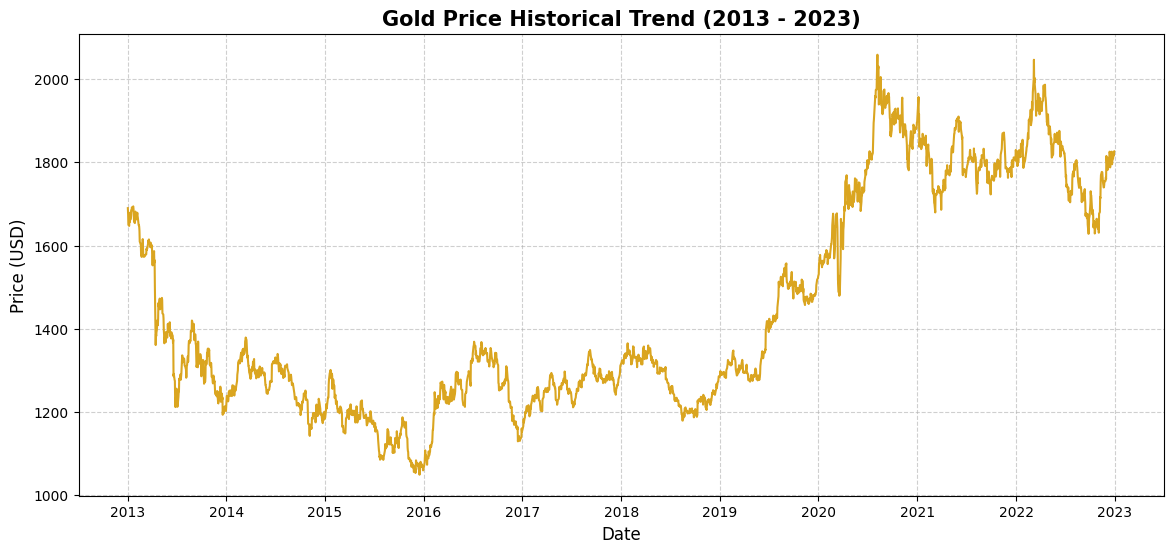


3. Distribution of Gold Price


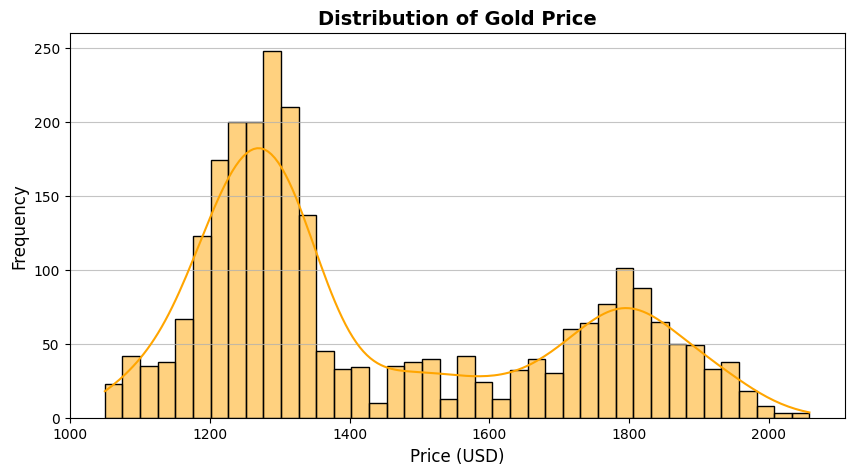


4. Yearly Boxplot


/tmp/ipykernel_2336/1153443077.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Year', y='Price', data=df, palette='YlOrBr')


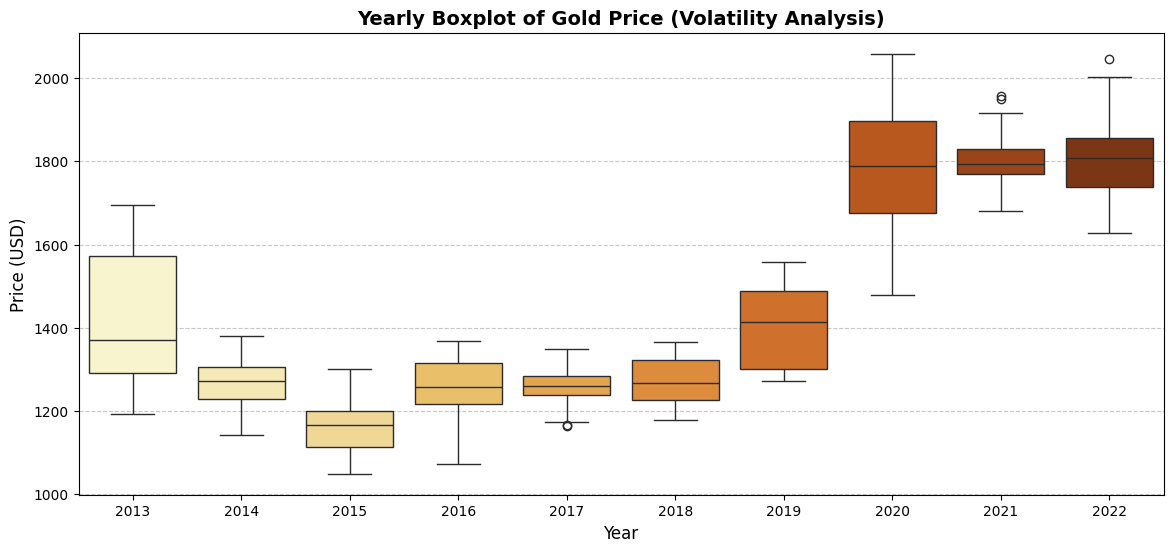

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("1. Basic Statistics of Gold Price")
# Display basic statistical details (mean, std, min, max) for the 'Price' column
display(df[['Price']].describe())

# Time Series Plot
# Visualize the historical trend of the Gold Price over the years
print("\n2. The historical trend of the Gold Price")
plt.figure(figsize=(14, 6))
plt.plot(df['Date'], df['Price'], color='goldenrod', linewidth=1.5)
plt.title('Gold Price Historical Trend (2013 - 2023)', fontsize=15, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Distribution Plot
# Check how the price values are distributed (Normal distribution, skewed, etc.)
print("\n3. Distribution of Gold Price")
plt.figure(figsize=(10, 5))
sns.histplot(df['Price'], kde=True, color='orange', bins=40, edgecolor='black')
plt.title('Distribution of Gold Price', fontsize=14, fontweight='bold')
plt.xlabel('Price (USD)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', alpha=0.75)
plt.show()

# Yearly Boxplot (Trend & Outliers)
# Extract 'Year' to analyze volatility and outliers year by year
print("\n4. Yearly Boxplot")
df['Year'] = df['Date'].dt.year
plt.figure(figsize=(14, 6))
sns.boxplot(x='Year', y='Price', data=df, palette='YlOrBr')
plt.title('Yearly Boxplot of Gold Price (Volatility Analysis)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Drop the 'Year' column after EDA so it doesn't affect the modeling steps
df = df.drop(columns=['Year'])

**Yearly Volatility and Trend Analysis**

-2013 - 2018: A dormant market. Gold prices remained low and highly stable (around the $1,200 - $1,300 range).

-2019: Broke out of the sideways trend and began a strong upward momentum.

-2020: The most turbulent year. The abnormally long box indicates extreme price volatility. Prices surged to new peaks (around $1,800 - $2,000).

-2021 - 2022: Gold established a new baseline (anchored high at ~$1,800), but the market stabilized.

# **II. Prepare univariate data**

**Splitting data(Train, Val, Test)**

Data Split Summary:
Train rows: 1806 | Val rows: 517 | Test rows: 260


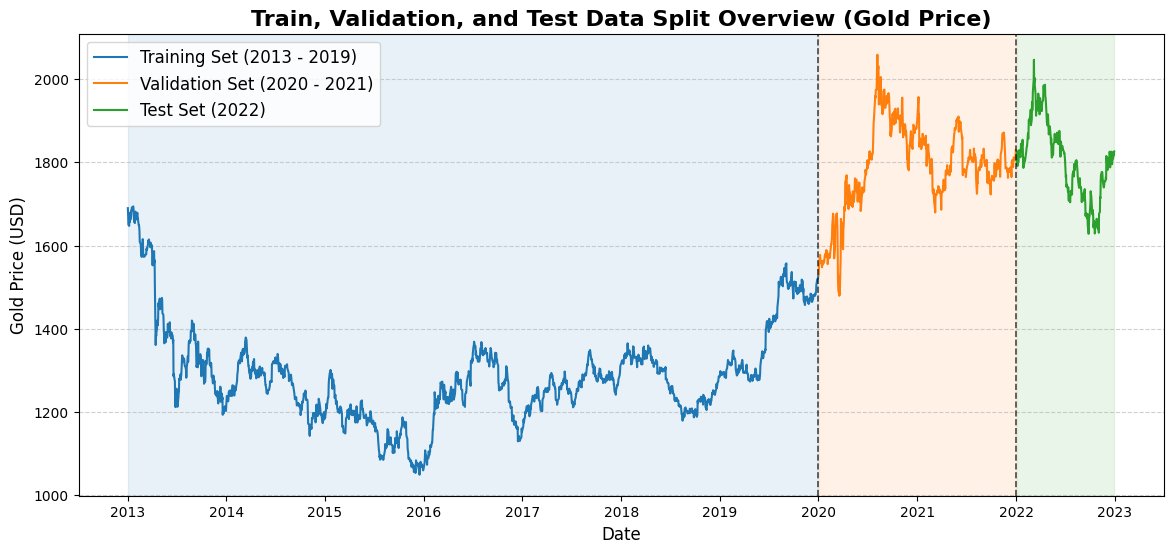

In [ ]:
import matplotlib.pyplot as plt
# Training set: 2013 - 2019
train_df = df[df['Date'].dt.year <= 2019]
# Validation set: 2020 - 2021
val_df = df[(df['Date'].dt.year >= 2020) & (df['Date'].dt.year <= 2021)]
# Test set: 2022
test_df = df[df['Date'].dt.year == 2022]

print(f"Data Split Summary:")
print(f"Train rows: {len(train_df)} | Val rows: {len(val_df)} | Test rows: {len(test_df)}")

plt.figure(figsize=(14, 6))

# Plot the price line for each dataset (Using 'Price' column)
plt.plot(train_df['Date'], train_df['Price'], label='Training Set (2013 - 2019)', color='#1f77b4', linewidth=1.5)
plt.plot(val_df['Date'], val_df['Price'], label='Validation Set (2020 - 2021)', color='#ff7f0e', linewidth=1.5)
plt.plot(test_df['Date'], test_df['Price'], label='Test Set (2022)', color='#2ca02c', linewidth=1.5)

# Add vertical dashed lines to clearly indicate split boundaries
plt.axvline(train_df['Date'].max(), color='black', linestyle='--', linewidth=1.2, alpha=0.7)
plt.axvline(val_df['Date'].max(), color='black', linestyle='--', linewidth=1.2, alpha=0.7)

# Add background shading to easily identify each region
plt.axvspan(train_df['Date'].min(), train_df['Date'].max(), color='#1f77b4', alpha=0.1)
plt.axvspan(val_df['Date'].min(), val_df['Date'].max(), color='#ff7f0e', alpha=0.1)
plt.axvspan(test_df['Date'].min(), test_df['Date'].max(), color='#2ca02c', alpha=0.1)

# Format the plot (Title, axis labels, legend)
plt.title('Train, Validation, and Test Data Split Overview (Gold Price)', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Gold Price (USD)', fontsize=12)
plt.legend(loc='upper left', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.show()

**Feature Scaling (Normalization)**

In [ ]:
scaler = MinMaxScaler(feature_range=(0, 1))
# Extract Price values for scaling
train_values = train_df['Price'].values.reshape(-1, 1)
val_values = val_df['Price'].values.reshape(-1, 1)
test_values = test_df['Price'].values.reshape(-1, 1)

# Fit only on training data to prevent data leakage
train_scaled = scaler.fit_transform(train_values)

# Transform validation and test data using the scaler fitted on train
val_scaled = scaler.transform(val_values)
test_scaled = scaler.transform(test_values)

**Create Sliding Window **

In [ ]:
def create_dataset(dataset, window_size=9):
    X, y = [], []
    for i in range(len(dataset) - window_size):
        X.append(dataset[i : (i + window_size), 0])
        y.append(dataset[i + window_size, 0])
    return np.array(X), np.array(y)

window_size = 21
X_train, y_train = create_dataset(train_scaled, window_size)
X_val, y_val     = create_dataset(val_scaled, window_size)
X_test, y_test   = create_dataset(test_scaled, window_size)

**Convert and Reshape to Numpy Arrays**

In [ ]:
# Reshape X to 3D: [samples, time_steps, features]
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_val   = np.reshape(X_val, (X_val.shape[0], X_val.shape[1], 1))
X_test  = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

# Reshape y to 2D: [samples, 1]
y_train = np.reshape(y_train, (-1, 1))
y_val   = np.reshape(y_val, (-1, 1))
y_test  = np.reshape(y_test, (-1, 1))

# Print Shapes to Verify
print('--- Final Data Shapes ---')
print(f'X_train Shape: {X_train.shape} | y_train Shape: {y_train.shape}')
print(f'X_val   Shape: {X_val.shape} | y_val   Shape: {y_val.shape}')
print(f'X_test  Shape: {X_test.shape} | y_test  Shape: {y_test.shape}')

--- Final Data Shapes ---
X_train Shape: (1785, 21, 1) | y_train Shape: (1785, 1)
X_val   Shape: (496, 21, 1) | y_val   Shape: (496, 1)
X_test  Shape: (239, 21, 1) | y_test  Shape: (239, 1)


# **III. Build and evaluate Model 1A (LSTM)**

**1. Build model**

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers

class ManualLSTMCell(layers.Layer):
    def __init__(self, units):
        super(ManualLSTMCell, self).__init__()
        self.units = units
        self.state_size = [units, units] # (hidden_state, cell_state)

    def build(self, input_shape):
        input_dim = input_shape[-1]
        # weight mat for all 4 gates atstime(f, i, C, o)
        self.W = self.add_weight(shape=(input_dim, self.units * 4), initializer='glorot_uniform', name='W')
        self.U = self.add_weight(shape=(self.units, self.units * 4), initializer='glorot_uniform', name='U')
        self.b = self.add_weight(shape=(self.units * 4,), initializer='zeros', name='b')

    def call(self, inputs, states):
        h_prev, c_prev = states
        # Matrix multiplication: xW + hU + b
        z = tf.matmul(inputs, self.W) + tf.matmul(h_prev, self.U) + self.b

        # split result for  4 gates
        i, f, c_candidate, o = tf.split(z, num_or_size_splits=4, axis=-1)

        # activation func
        i = tf.sigmoid(i)
        f = tf.sigmoid(f)
        c_candidate = tf.tanh(c_candidate)
        o = tf.sigmoid(o)

        # update Cell State
        c_next = f * c_prev + i * c_candidate

        # update Hidden State
        h_next = o * tf.tanh(c_next)

        return h_next, [h_next, c_next]
model_uni = tf.keras.Sequential([
    layers.Input(shape=(window_size, 1)),
    layers.RNN(ManualLSTMCell(64)),
    layers.Dropout(0.2),
    layers.Dense(1)
])
model_uni.compile(optimizer='adam', loss='mean_squared_error')

**2. Train model**

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

print("Training model LSTM Univariate...")
history = model_uni.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=1
)
model_uni.save_weights('lstm_univariate_weights.weights.h5')

Training model LSTM Univariate...
Epoch 1/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.0229 - val_loss: 0.0039
Epoch 2/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0025 - val_loss: 0.0078
Epoch 3/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0021 - val_loss: 0.0201
Epoch 4/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0018 - val_loss: 0.0049
Epoch 5/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0016 - val_loss: 0.0059
Epoch 6/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0015 - val_loss: 0.0032
Epoch 7/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0015 - val_loss: 0.0023
Epoch 8/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0015 - val_loss: 0.0022
Epoch 9/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0014 - val_loss: 0.0022
Epoch 10/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0013 - val_loss: 0.0022
Epoch 11/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0013 - val_loss: 0.0030
Epoch 12/50
56/56 ━━━━━━━━━━━

**3. Evaluate model**

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# predict on Test set
y_pred_scaled = model_uni.predict(X_test)

# convert to USD
y_pred = scaler.inverse_transform(y_pred_scaled)
y_true = scaler.inverse_transform(y_test.reshape(-1, 1))

# evaluate value
mse = mean_squared_error(y_true, y_pred)
mae = mean_absolute_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)

print(f"Result File Uni - LSTM:\n MSE - sai số bình quân: {mse:.4f}\n MAE - Mean Absolute Error: {mae:.4f}\n R^2 - độ khớp mô hình: {r2:.4f}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Result File Uni - LSTM:
 MSE - sai số bình quân: 345.8594
 MAE - Mean Absolute Error: 14.3657
 R^2 - độ khớp mô hình: 0.9614


**4. Visualizing Results**

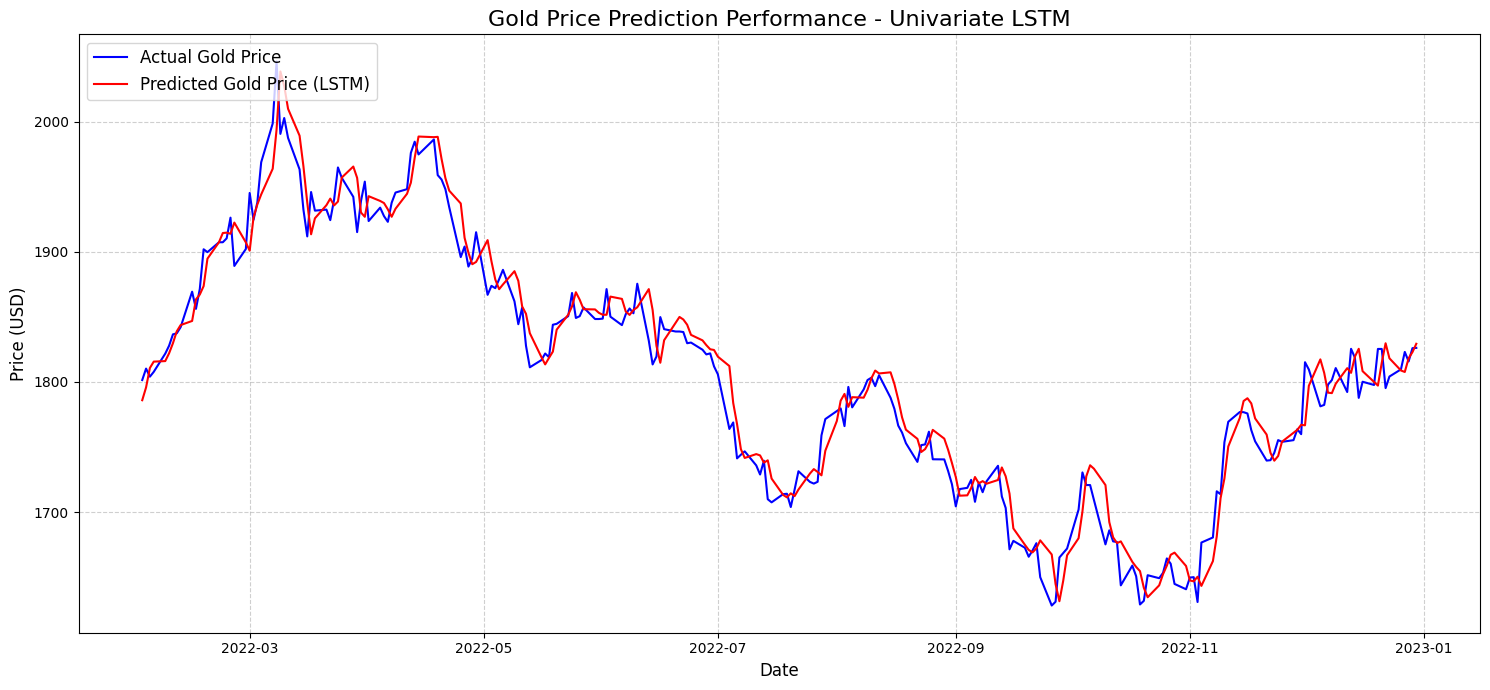

In [ ]:
import matplotlib.pyplot as plt

# convert to USD
y_test_true = scaler.inverse_transform(y_test)
y_test_pred = scaler.inverse_transform(y_pred_scaled)

# take days respectively
test_dates = test_df['Date'].iloc[window_size:].values

plt.figure(figsize=(15, 7), facecolor='white')
ax = plt.gca()
ax.set_facecolor('white')

plt.plot(test_dates, y_test_true, color='blue', label='Actual Gold Price', linewidth=1.5)
plt.plot(test_dates, y_test_pred, color='red', label='Predicted Gold Price (LSTM)', linewidth=1.5)

plt.title('Gold Price Prediction Performance - Univariate LSTM', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.6)

plt.legend(loc='upper left', fontsize=12, facecolor='white')

plt.tight_layout()
plt.savefig('lstm_univariate_results.png', dpi=300)
plt.show()

**Model Performance Analysis**

-The figure compares actual gold prices with LSTM predicted prices using a 9-day sliding window to forecast the next day.

-The predicted values closely follow the overall trend of the actual prices, showing that the LSTM model captures the temporal patterns of the gold price series effectively.

-During sharp fluctuations, the predicted curve tends to lag behind and appear smoother than the actual price.

->Overall, the model provides reasonably accurate short-term predictions, but improvements can be made by increasing the window size and extending the model to a multivariate framework with additional relevant variables.





# **Build and evaluate Model 1B (CNN-LSTM)**

**1. Build model**

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Sequential

model_cnn_lstm = Sequential([
    layers.Input(shape=(window_size, 1)),
    # CNN: Feature exatraction
    layers.Conv1D(filters=64, kernel_size=3, activation='relu', padding='same'),
    layers.MaxPooling1D(pool_size=2),
    # LSTM: Sequence processing
    layers.RNN(ManualLSTMCell(64), return_sequences=False),
    layers.Dropout(0.2),
    layers.Dense(1)
])

model_cnn_lstm.compile(optimizer='adam', loss='mean_squared_error')
model_cnn_lstm.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_6 (Conv1D)               │ (None, 21, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_6 (MaxPooling1D)  │ (None, 10, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rnn_7 (RNN)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,345 (130.25 KB)

 Trainable params: 33,345 (130.25 KB)

 Non-trainable params: 0 (0.00 B)

**2. Train model**

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

print("Training model CNN-LSTM...")
history_cnn_lstm = model_cnn_lstm.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

model_cnn_lstm.save_weights('cnn_lstm_univariate_weights.weights.h5')

Training model CNN-LSTM...
Epoch 1/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0138 - val_loss: 0.0128
Epoch 2/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0024 - val_loss: 0.0042
Epoch 3/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0021 - val_loss: 0.0039
Epoch 4/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0019 - val_loss: 0.0037
Epoch 5/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0017 - val_loss: 0.0026
Epoch 6/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0018 - val_loss: 0.0075
Epoch 7/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0015 - val_loss: 0.0037
Epoch 8/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0015 - val_loss: 0.0104
Epoch 9/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0016 - val_loss: 0.0043
Epoch 10/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0016 - val_loss: 0.0070
Epoch 11/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0015 - val_loss: 0.0034
Epoch 12/50
56/56 ━━━━━━━━━━━━━━━━━━

**3. Evaluate model**

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

y_pred_scaled_cl = model_cnn_lstm.predict(X_test)

# convert to USD
y_pred_cl = scaler.inverse_transform(y_pred_scaled_cl)
y_true = scaler.inverse_transform(y_test.reshape(-1, 1))

mse_cl = mean_squared_error(y_true, y_pred_cl)
mae_cl = mean_absolute_error(y_true, y_pred_cl)
r2_cl = r2_score(y_true, y_pred_cl)

print(f"\n--- Results of Uni - CNN-LSTM ---")
print(f"MSE: {mse_cl:.4f}")
print(f"MAE: {mae_cl:.4f}")
print(f"R2 Score: {r2_cl:.4f}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step

--- Results of Uni - CNN-LSTM ---
MSE: 834.2350
MAE: 22.7567
R2 Score: 0.9070


**4. Visualizing result**

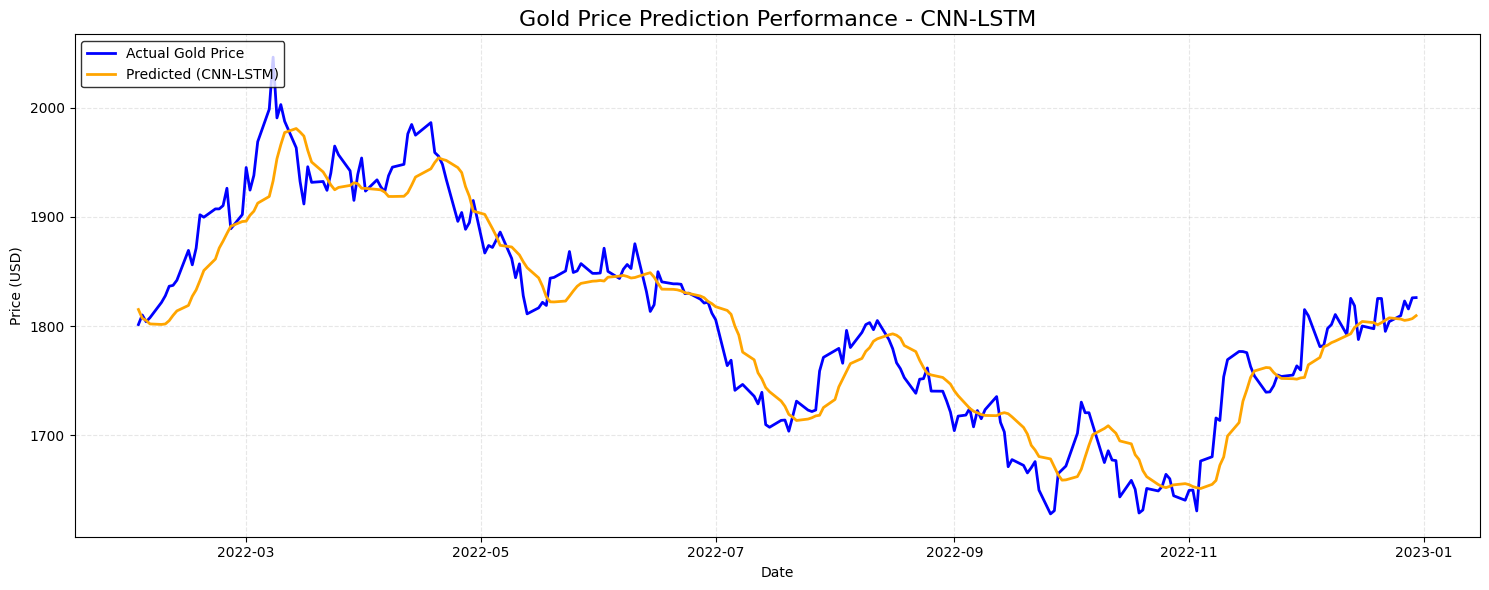

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6), facecolor='white')
ax = plt.gca()
ax.set_facecolor('white')

plt.plot(test_dates, y_test_true, color='blue', label='Actual Gold Price', lw=2)
plt.plot(test_dates, y_pred_cl, color='orange', label='Predicted (CNN-LSTM)', lw=2)

plt.title('Gold Price Prediction Performance - CNN-LSTM', fontsize=16)
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='black')

plt.tight_layout()
plt.savefig('cnn_lstm_results.png', dpi=300)
plt.show()

# **IV. Build and evaluate Model 2 (CNN-GRU).**

**1. Build model**

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Layer, Conv1D, MaxPooling1D, Dense, Dropout, Input
from tensorflow.keras.models import Sequential
import matplotlib.pyplot as plt

class CustomGRU(Layer):
    def __init__(self, units, return_sequences=False, **kwargs):
        super(CustomGRU, self).__init__(**kwargs)
        self.units = units
        self.return_sequences = return_sequences

    def build(self, input_shape):
        input_dim = input_shape[-1]

        # 1. Cổng cập nhật: quyết định giữ/bỏ bao nhiêu % thông tin
        self.W_z = self.add_weight(shape=(input_dim, self.units), initializer='glorot_uniform', name='W_z')
        self.U_z = self.add_weight(shape=(self.units, self.units), initializer='glorot_uniform', name='U_z')
        self.b_z = self.add_weight(shape=(self.units,), initializer='zeros', name='b_z')

        # 2. Cổng khôi phục: quyết định quên bao nhiêu % quá khứ
        self.W_r = self.add_weight(shape=(input_dim, self.units), initializer='glorot_uniform', name='W_r')
        self.U_r = self.add_weight(shape=(self.units, self.units), initializer='glorot_uniform', name='U_r')
        self.b_r = self.add_weight(shape=(self.units,), initializer='zeros', name='b_r')

        # 3. Tính toán bộ nhớ tạm/ứng viên
        self.W_h = self.add_weight(shape=(input_dim, self.units), initializer='glorot_uniform', name='W_h')
        self.U_h = self.add_weight(shape=(self.units, self.units), initializer='glorot_uniform', name='U_h')
        self.b_h = self.add_weight(shape=(self.units,), initializer='zeros', name='b_h')

        super(CustomGRU, self).build(input_shape)

    def call(self, inputs):
        batch_size = tf.shape(inputs)[0]
        time_steps = inputs.shape[1]

        h_t = tf.zeros((batch_size, self.units))
        outputs = []

        for t in range(time_steps):
            x_t = inputs[:, t, :]
            z_t = tf.sigmoid(tf.matmul(x_t, self.W_z) + tf.matmul(h_t, self.U_z) + self.b_z)
            r_t = tf.sigmoid(tf.matmul(x_t, self.W_r) + tf.matmul(h_t, self.U_r) + self.b_r)
            h_tilde = tf.tanh(tf.matmul(x_t, self.W_h) + tf.matmul(r_t * h_t, self.U_h) + self.b_h)
            h_t = (1 - z_t) * h_t + z_t * h_tilde

            outputs.append(h_t)
        outputs = tf.stack(outputs, axis=1)

        if self.return_sequences:
            return outputs
        else:
            return h_t

print("--- Building CNN-GRU (Funnel Architecture) ---")

model_cnn_gru = Sequential()

# CNN
model_cnn_gru.add(Input(shape=(window_size, 1)))
model_cnn_gru.add(Conv1D(filters=64, kernel_size=3, activation='relu', padding='same'))
model_cnn_gru.add(MaxPooling1D(pool_size=2))

# GRU 1
model_cnn_gru.add(CustomGRU(units=64, return_sequences=True))
model_cnn_gru.add(Dropout(0.2))

# GRU 2
model_cnn_gru.add(CustomGRU(units=32, return_sequences=False))
model_cnn_gru.add(Dropout(0.2))

model_cnn_gru.add(Dense(units=1))

model_cnn_gru.compile(optimizer='adam', loss='mean_squared_error')
model_cnn_gru.summary()

--- Building CNN-GRU (Funnel Architecture) ---


Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_7 (Conv1D)               │ (None, 21, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 10, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ custom_gru_12 (CustomGRU)       │ (None, 10, 64)         │        24,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 10, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ custom_gru_13 (CustomGRU)       │ (None, 32)             │         9,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,369 (134.25 KB)

 Trainable params: 34,369 (134.25 KB)

 Non-trainable params: 0 (0.00 B)

**2. Train model**

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
print("Đang huấn luyện mô hình CNN-GRU...")
history_cnn_gru = model_cnn_gru.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

model_cnn_gru.save_weights('cnn_gru_univariate_weights.weights.h5')

Đang huấn luyện mô hình CNN-GRU...
Epoch 1/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - loss: 0.0141 - val_loss: 0.0175
Epoch 2/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0046 - val_loss: 0.0096
Epoch 3/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0036 - val_loss: 0.0095
Epoch 4/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0039 - val_loss: 0.0186
Epoch 5/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0031 - val_loss: 0.0061
Epoch 6/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0029 - val_loss: 0.0145
Epoch 7/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0029 - val_loss: 0.0099
Epoch 8/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0027 - val_loss: 0.0032
Epoch 9/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0024 - val_loss: 0.0061
Epoch 10/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0022 - val_loss: 0.0079
Epoch 11/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0022 - val_loss: 0.0050
Epoch 12/50
56/56 ━━━━━━━━━

**3. Evaluate model**

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Dự báo trên tập Test
y_pred_scaled_cnn_gru = model_cnn_gru.predict(X_test)

test_dates = test_df['Date'].iloc[window_size:].values
# Đưa về đơn vị USD
y_pred_cnn_gru = scaler.inverse_transform(y_pred_scaled_cnn_gru)
y_true = scaler.inverse_transform(y_test.reshape(-1, 1))

mse_cg = mean_squared_error(y_true, y_pred_cnn_gru)
mae_cg = mean_absolute_error(y_true, y_pred_cnn_gru)
r2_cg = r2_score(y_true, y_pred_cnn_gru)

print(f"\n--- Kết quả File Uni - CNN-GRU ---")
print(f"MSE: {mse_cg:.4f}")
print(f"MAE: {mae_cg:.4f}")
print(f"R2 Score: {r2_cg:.4f}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step

--- Kết quả File Uni - CNN-GRU ---
MSE: 1078.4833
MAE: 25.9042
R2 Score: 0.8797


**4. Visualizing**

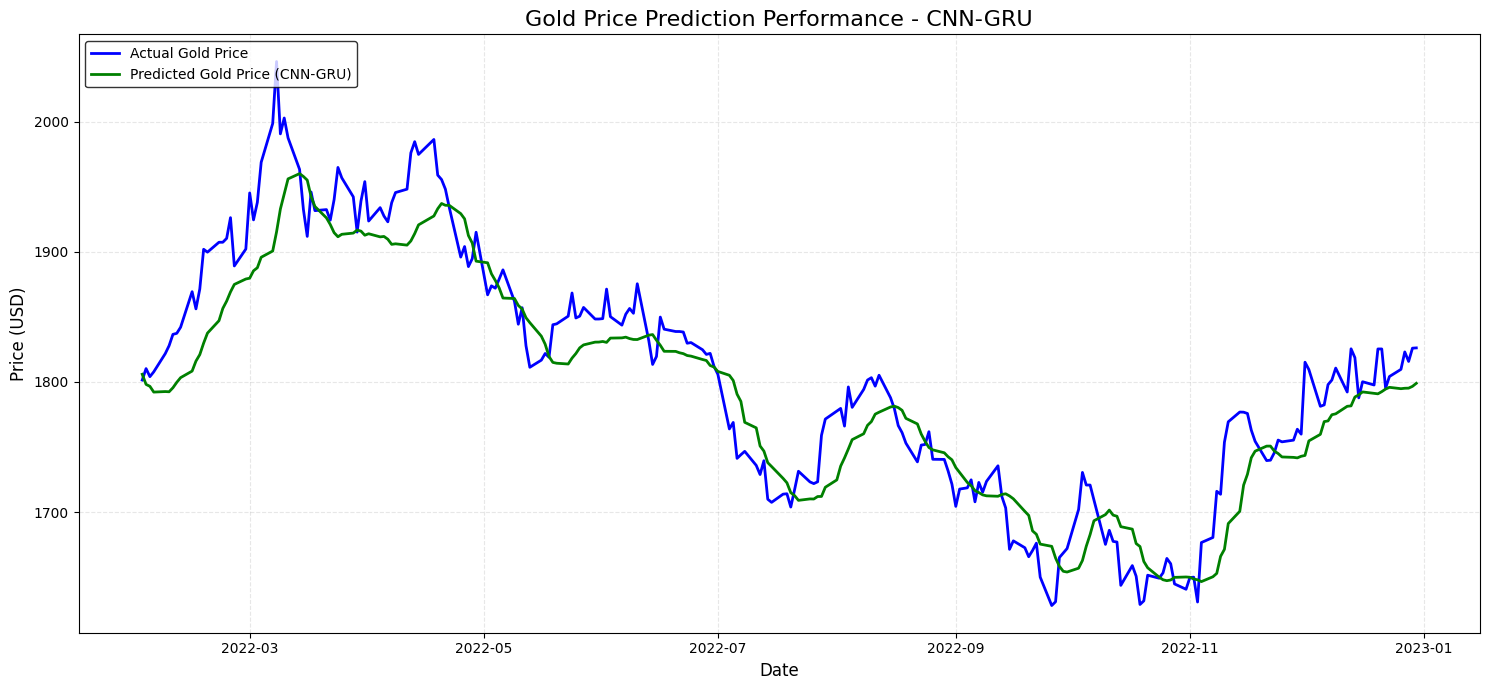

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 7), facecolor='white')
ax = plt.gca()
ax.set_facecolor('white')

plt.plot(test_dates, y_true, color='blue', label='Actual Gold Price', linewidth=2)
plt.plot(test_dates, y_pred_cnn_gru, color='green', label='Predicted Gold Price (CNN-GRU)', linewidth=2)

plt.title('Gold Price Prediction Performance - CNN-GRU', fontsize=16, color='black')
plt.xlabel('Date', fontsize=12, color='black')
plt.ylabel('Price (USD)', fontsize=12, color='black')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='black')

plt.tight_layout()
plt.savefig('cnn_gru_results.png', dpi=300)
plt.show()

**Model Performance Analysis**

-The figure compares actual gold prices with predictions from the CNN-GRU model. The predicted curve generally follows the overall trend of the actual price series, indicating that the model can capture the main temporal patterns of gold price movements.

-However, some deviations appear during periods of strong fluctuations, where the predicted values are slightly smoother and occasionally lag behind the actual prices.

-The model achieved an R² score of 0.9421, which indicates a strong predictive capability but is slightly lower than the LSTM model (R² = 0.9588).

-This suggests that while CNN-GRU can effectively learn the underlying patterns in the data, the LSTM model performed better for this dataset in terms of overall prediction accuracy.

# **Build and evaluate Model 2 (GRU).**

**1. Build model**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers, Sequential
import tensorflow as tf
from tensorflow.keras.layers import Layer, Conv1D, MaxPooling1D, Dense, Dropout, Input
import matplotlib.pyplot as plt
model_gru = Sequential()

model_gru.add(Input(shape=(window_size, 1)))

# Corrected model name from model_cnn_gru to model_gru
model_gru.add(CustomGRU(units=64, return_sequences=True))
model_gru.add(Dropout(0.2))

model_gru.add(CustomGRU(units=32, return_sequences=False))
model_gru.add(Dropout(0.2))

# Add the final Dense layer for the output
model_gru.add(Dense(1))

model_gru.compile(optimizer='adam', loss='mean_squared_error')
model_gru.summary()

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ custom_gru_14 (CustomGRU)       │ (None, 21, 64)         │        12,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 21, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ custom_gru_15 (CustomGRU)       │ (None, 32)             │         9,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,017 (86.00 KB)

 Trainable params: 22,017 (86.00 KB)

 Non-trainable params: 0 (0.00 B)

 **2. Train model**

2. Training Model
Epoch 1/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 20s 58ms/step - loss: 0.0194 - val_loss: 0.0041
Epoch 2/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0047 - val_loss: 0.0037
Epoch 3/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0036 - val_loss: 9.3631e-04
Epoch 4/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0035 - val_loss: 0.0011
Epoch 5/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0034 - val_loss: 6.0715e-04
Epoch 6/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0030 - val_loss: 9.8456e-04
Epoch 7/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0027 - val_loss: 0.0019
Epoch 8/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 0.0026 - val_loss: 0.0013
Epoch 9/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0024 - val_loss: 6.3337e-04
Epoch 10/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0024 - val_loss: 5.1736e-04
Epoch 11/100
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0021 - val_loss: 6.6714e-04
Epoch 12/

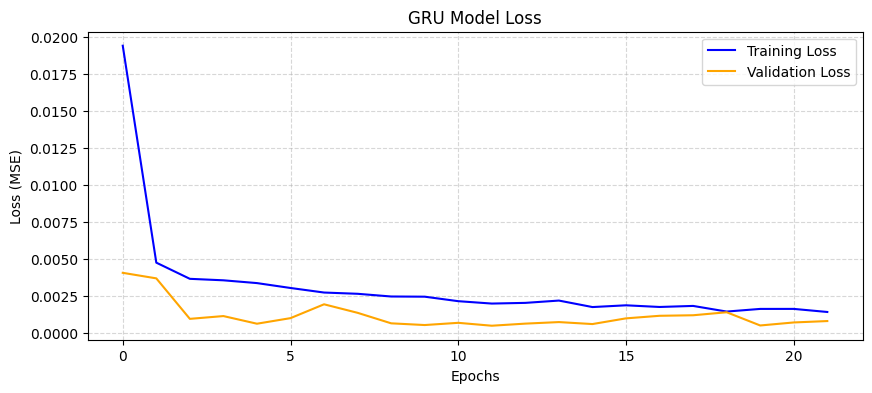

done


In [ ]:
print("2. Training Model")
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
#earlystopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,             # dừng nếu 10 epoch không cải thiện
    restore_best_weights=True
)

history_g = model_gru.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop]
)

print("3. Plotting Training Loss")
plt.figure(figsize=(10, 4))
plt.plot(history_g.history['loss'], label='Training Loss', color='blue')
plt.plot(history_g.history['val_loss'], label='Validation Loss', color='orange') # Corrected: used history_g instead of history_cg
plt.title('GRU Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()
print("done")

**3. Evaluate model**

8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 207ms/step

--- Kết quả File Uni -GRU ---
MSE: 513.6533
MAE: 17.4715
R2 Score: 0.9427


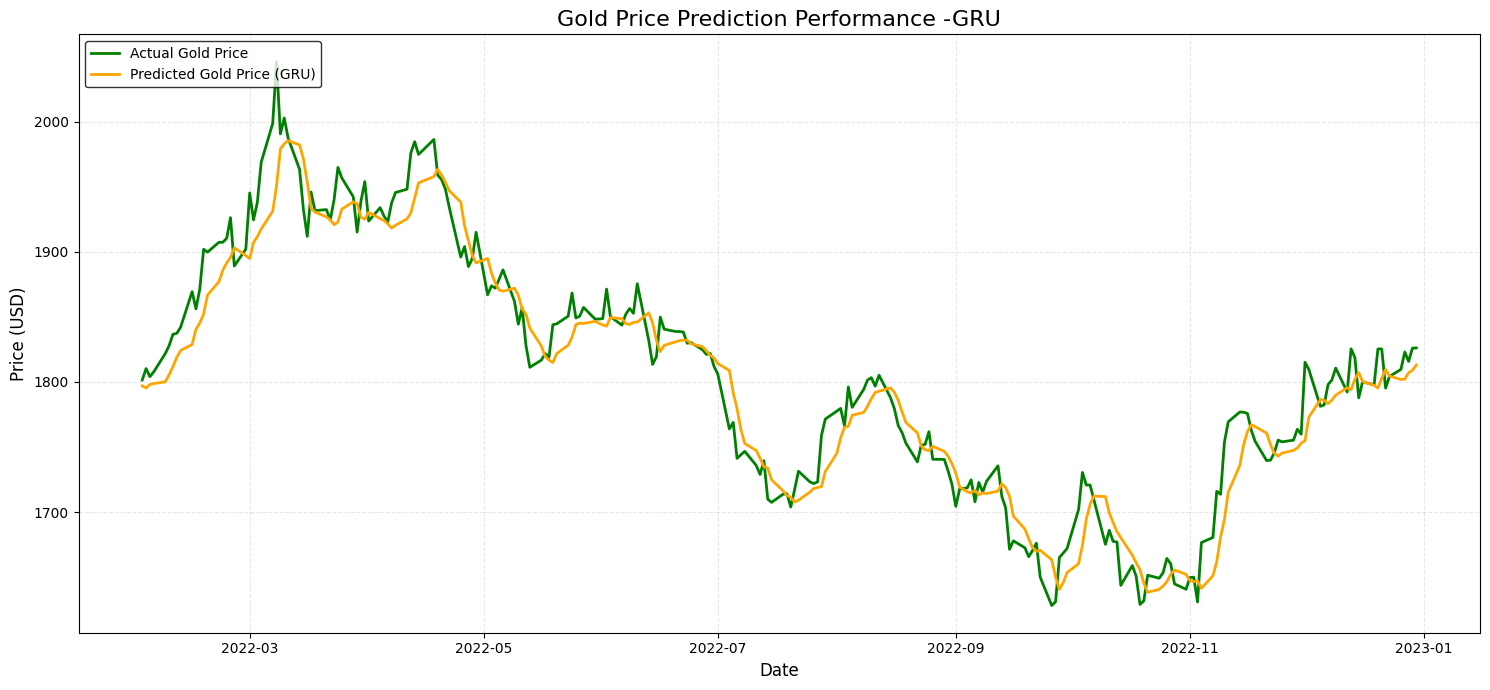

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Dự báo trên tập Test
y_pred_scaled_gru = model_gru.predict(X_test)
test_dates = test_df['Date'].values[window_size:]
# Đưa về đơn vị USD
y_pred_gru = scaler.inverse_transform(y_pred_scaled_gru)
y_true = scaler.inverse_transform(y_test.reshape(-1, 1))

mse_cg = mean_squared_error(y_true, y_pred_gru)
mae_cg = mean_absolute_error(y_true, y_pred_gru)
r2_cg = r2_score(y_true, y_pred_gru)

print(f"\n--- Kết quả File Uni -GRU ---")
print(f"MSE: {mse_cg:.4f}")
print(f"MAE: {mae_cg:.4f}")
print(f"R2 Score: {r2_cg:.4f}")
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 7), facecolor='white')
ax = plt.gca()
ax.set_facecolor('white')

plt.plot(test_dates, y_true, color='green', label='Actual Gold Price', linewidth=2)
plt.plot(test_dates, y_pred_gru, color='orange', label='Predicted Gold Price (GRU)', linewidth=2)

plt.title('Gold Price Prediction Performance -GRU', fontsize=16, color='black')
plt.xlabel('Date', fontsize=12, color='black')
plt.ylabel('Price (USD)', fontsize=12, color='black')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='black')

plt.tight_layout()
plt.savefig('gru_results.png', dpi=300)
plt.show()